# CS-871 Machine Learning | Assignment #2 | Dataset 2
##Dataset: ML Students Data Collection for an Assignment (Responses)  

## Step 1 — Upload the Excel dataset


In [3]:
import pandas as pd
import numpy as np
from IPython.display import display
from pathlib import Path
# Colab: upload the supplied spreadsheet when it is not already in the working directory.
DATA_FILE = Path("/mnt/data/ML Students Data Collection for an Assignment (Responses)(2).xlsx")
if not DATA_FILE.exists():
    from google.colab import files
    uploaded = files.upload()
    DATA_FILE = Path(next(name for name in uploaded if name.lower().endswith(".xlsx")))
df_raw = pd.read_excel(DATA_FILE)
print("Dataset:", DATA_FILE.name, "| Original shape:", df_raw.shape)
display(df_raw.head())

Saving ML Students Data Collection for an Assignment (Responses).xlsx to ML Students Data Collection for an Assignment (Responses) (1).xlsx
Dataset: ML Students Data Collection for an Assignment (Responses) (1).xlsx | Original shape: (78, 13)


,Timestamp,What is your Gender,Which Province do you belong to,Parental level of education,Matric Percentage,FSc Percentage,UG CGPA,University from where you did your UG,Did you join any preparation course for MS Admission,Current CGPA MS,Last Semester GPA (SGPA) MS,Which semester are you currently studying in?,How many credit hours have you complete till now?
0,2026-09-23 11:24:22.770,Male,Punjab,Middle,91.64,86.09,3.47,Bahauddin Zakariya University,No,3.56,NaN,NaN,NaN
1,2026-09-24 13:40:29.037,Female,Punjab,FA,0.89,0.94,3.59,International islamic university Islamabad,No,NaN,NaN,1st,NaN
2,2026-09-24 13:41:48.421,Male,Kashmir,B.A,67.00,70,3.3,University of azad jamu and kashmir,No,none,none,first,none
3,2026-09-24 13:43:02.292,Female,Punjab,BS,0.94,0.81,3.13,Fast university Islamabad,No,NaN,NaN,1st semester,0
4,2026-09-24 13:48:25.026,Male,Punjab,BSc,82.00,84,2.97,Middle East Technical University,No,NaN,NaN,1,0


## Step 2 — Inspect columns, missing values, duplicates, and target
Inspect the raw survey before changing anything.

In [4]:
print("Column names:")
for i, col in enumerate(df_raw.columns, start=1):
    print(f"{i:02d}. {col}")
print("\nRaw duplicates:", df_raw.duplicated().sum())
print("\nRaw missing values:")
print(df_raw.isna().sum())
print("\nUG CGPA values:")
print(pd.to_numeric(df_raw["UG CGPA"], errors="coerce").describe())

Column names:
01. Timestamp
02. What is your Gender
03. Which Province do you belong to
04. Parental level of education
05. Matric Percentage
06. FSc Percentage
07. UG CGPA
08. University from where you did your UG
09. Did you join any preparation course for MS Admission
10. Current CGPA MS
11. Last Semester GPA (SGPA) MS
12. Which semester are you currently studying in?
13. How many credit hours have you complete till now?

Raw duplicates: 0

Raw missing values:
Timestamp                                                0
What is your Gender                                      0
Which Province do you belong to                          0
Parental level of education                              2
Matric Percentage                                        0
FSc Percentage                                           0
UG CGPA                                                  2
University from where you did your UG                    2
Did you join any preparation course for MS Admission     4
C

## Step 3 — Clean the survey data
Convert percentage fractions (e.g., `0.94`) to percentage units (`94`). Normalize parental education categories. Remove rows without a valid UG CGPA. Drop post-UG variables to avoid target leakage and use a compact, interpretable feature set.

In [5]:
df = df_raw.copy()
df.columns = df.columns.str.strip()
# Normalize missing-value tokens across text columns.
missing_tokens = {"": np.nan, "none": np.nan, "n/a": np.nan, "na": np.nan, "null": np.nan, "nan": np.nan, "-": np.nan}
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].astype("string").str.strip()
    df[col] = df[col].replace(r"^\s*$", pd.NA, regex=True)
    df[col] = df[col].replace({k: pd.NA for k in missing_tokens if k})
    df[col] = df[col].replace({k.upper(): pd.NA for k in missing_tokens if k})
# Ensure UG CGPA is numeric and within the standard 0-4 scale.
df["UG CGPA"] = pd.to_numeric(df["UG CGPA"], errors="coerce")
rows_before = len(df)
df = df.loc[df["UG CGPA"].between(0, 4)].copy()
# Convert fraction-style percentages to percentages; mark invalid values missing.
for col in ["Matric Percentage", "FSc Percentage"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    df.loc[df[col].between(0, 1, inclusive="both"), col] *= 100
    df.loc[~df[col].between(0, 100), col] = np.nan
# Normalize noisy parental education text into broad, reproducible categories.
def parent_education(value):
    if pd.isna(value):
        return "Unknown"
    v = str(value).lower().strip().replace(".", "")
    if any(k in v for k in ["phd", "doctorate", "doctoral"]):
        return "Doctorate"
    if any(k in v for k in ["master", "msc", "ms ", "mphil", "m phil", "mba", "ma "]) or v in {"ms", "ma", "m a", "m sc"}:
        return "Masters"
    if any(k in v for k in ["bachelor", "graduat", "undergrad", "bsc", "bs ", "b tech", "bcom", "bba"]) or v in {"bs", "ba", "b a", "bsc", "bcom", "bba"}:
        return "Bachelors"
    if any(k in v for k in ["fsc", "f sc", "inter", "hssc", "higher secondary", "fa "]) or v in {"fa", "f a", "ics"}:
        return "Intermediate"
    if any(k in v for k in ["matric", "ssc", "secondary", "middle", "primary", "school", "illiterate"]):
        return "School or Below"
    return "Other/Unclear"
df["Parental Education Group"] = df["Parental level of education"].apply(parent_education)
# Keep predictors available before/during UG study; exclude MS outcomes and admission preparation.
feature_columns = [
    "What is your Gender", "Which Province do you belong to",
    "Parental Education Group", "Matric Percentage", "FSc Percentage"
]
model_df = df[feature_columns + ["UG CGPA"]].copy()
print("Rows before:", rows_before, "| Valid UG CGPA rows:", len(model_df))
print("\nCleaned feature missing values:")
print(model_df.isna().sum())
print("\nParental education groups:")
print(model_df["Parental Education Group"].value_counts())
display(model_df.head())

Rows before: 78 | Valid UG CGPA rows: 74

Cleaned feature missing values:
What is your Gender                0
Which Province do you belong to    0
Parental Education Group           0
Matric Percentage                  0
FSc Percentage                     0
UG CGPA                            0
dtype: int64

Parental education groups:
Parental Education Group
Bachelors          30
Masters            18
Intermediate       10
Other/Unclear       9
School or Below     4
Unknown             3
Name: count, dtype: int64


,What is your Gender,Which Province do you belong to,Parental Education Group,Matric Percentage,FSc Percentage,UG CGPA
0,Male,Punjab,School or Below,91.64,86.09,3.47
1,Female,Punjab,Intermediate,89.00,94.0,3.59
2,Male,Kashmir,Bachelors,67.00,70.0,3.3
3,Female,Punjab,Bachelors,94.00,81.0,3.13
4,Male,Punjab,Bachelors,82.00,84.0,2.97


## Step 4 — Explore the cleaned target and academic-risk proxy
The classification label is derived from UG CGPA solely to reproduce the earlier classification workflow. It must not be described as observed student dropout.

REGRESSION TARGET SUMMARY
-------------------------
count        74.0
mean     3.065027
std      0.446406
min          0.79
25%       2.81725
50%           3.1
75%        3.3225
max          3.97
Name: UG CGPA, dtype: Float64

ACADEMIC RISK DISTRIBUTION
--------------------------
Class 0 (Not At Risk): 69 students (93.24%)
Class 1 (At Risk): 5 students (6.76%)

CLASS IMBALANCE CHECK
---------------------
Use stratified splitting and careful evaluation.
Class weighting may help during model training.


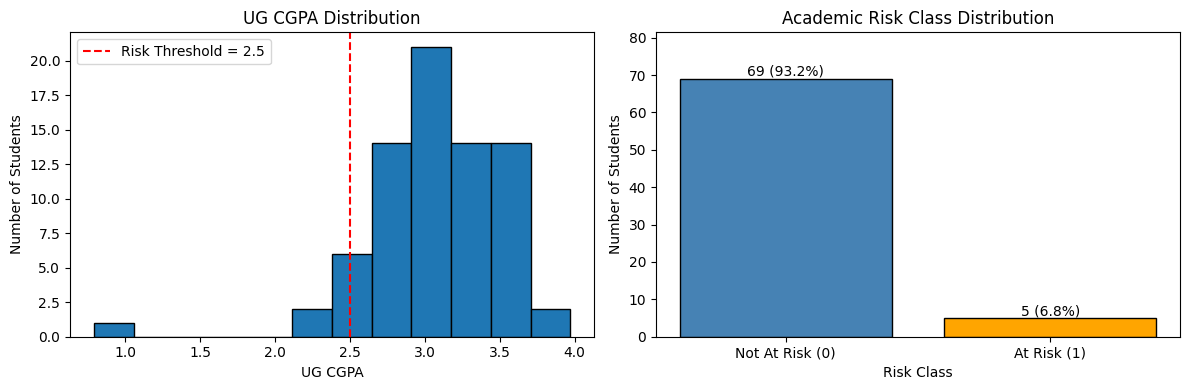

In [6]:
import matplotlib.pyplot as plt
import numpy as np

# Step 4: Explore UG CGPA and detect class imbalance
# Define the academic-risk proxy
# 0 = UG CGPA >= 2.5 (Not At Risk)
# 1 = UG CGPA < 2.5 (At Risk)
# This is not an actual dropout label.
model_df["academic_risk"] = (
    model_df["UG CGPA"] < 2.5
).astype(int)

# Display regression target statistics
print("REGRESSION TARGET SUMMARY")
print("-------------------------")
print(model_df["UG CGPA"].describe())

# Calculate class distribution
risk_counts = (
    model_df["academic_risk"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

risk_percentages = (
    risk_counts / risk_counts.sum() * 100
)

print("\nACADEMIC RISK DISTRIBUTION")
print("--------------------------")

for cls, label in [(0, "Not At Risk"), (1, "At Risk")]:
    print(
        f"Class {cls} ({label}): "
        f"{risk_counts[cls]} students "
        f"({risk_percentages[cls]:.2f}%)"
    )

# Check class imbalance
minority_count = risk_counts.min()
majority_count = risk_counts.max()

print("\nCLASS IMBALANCE CHECK")
print("---------------------")

if minority_count == 0:
    print("WARNING: Only one class is present.")
elif minority_count / majority_count < 0.20:
    print("WARNING: Severe class imbalance detected.")
    print("Use stratified splitting and careful evaluation.")
    print("Class weighting may help during model training.")
else:
    print("No severe class imbalance detected.")

# Create visualizations
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Graph 1: UG CGPA distribution
axes[0].hist(
    model_df["UG CGPA"],
    bins=12,
    edgecolor="black"
)

axes[0].axvline(
    x=2.5,
    color="red",
    linestyle="--",
    label="Risk Threshold = 2.5"
)

axes[0].set_title("UG CGPA Distribution")
axes[0].set_xlabel("UG CGPA")
axes[0].set_ylabel("Number of Students")
axes[0].legend()

# Graph 2: Academic-risk class distribution
bars = axes[1].bar(
    ["Not At Risk (0)", "At Risk (1)"],
    risk_counts.values,
    color=["steelblue", "orange"],
    edgecolor="black"
)

axes[1].set_title("Academic Risk Class Distribution")
axes[1].set_xlabel("Risk Class")
axes[1].set_ylabel("Number of Students")

# Display counts and percentages above bars
for bar, count, percentage in zip(
    bars,
    risk_counts.values,
    risk_percentages.values
):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.8,
        f"{count} ({percentage:.1f}%)",
        ha="center"
    )

axes[1].set_ylim(0, max(risk_counts.values) * 1.18)

plt.tight_layout()
plt.show()


## Step 4A — Missingness, Outliers, Correlations, and Distributions
Outliers are flagged with the IQR rule and reviewed rather than automatically removed. Percentages are normalized first. Correlations are descriptive, not causal.

Missing values after cleaning:


,Missing
What is your Gender,0
Which Province do you belong to,0
Parental Education Group,0
Matric Percentage,0
FSc Percentage,0
UG CGPA,0


,Variable,Lower IQR bound,Upper IQR bound,Flagged outliers
0,Matric Percentage,68.638,98.937,12
1,FSc Percentage,49.375,104.375,0
2,UG CGPA,2.059,4.080,1


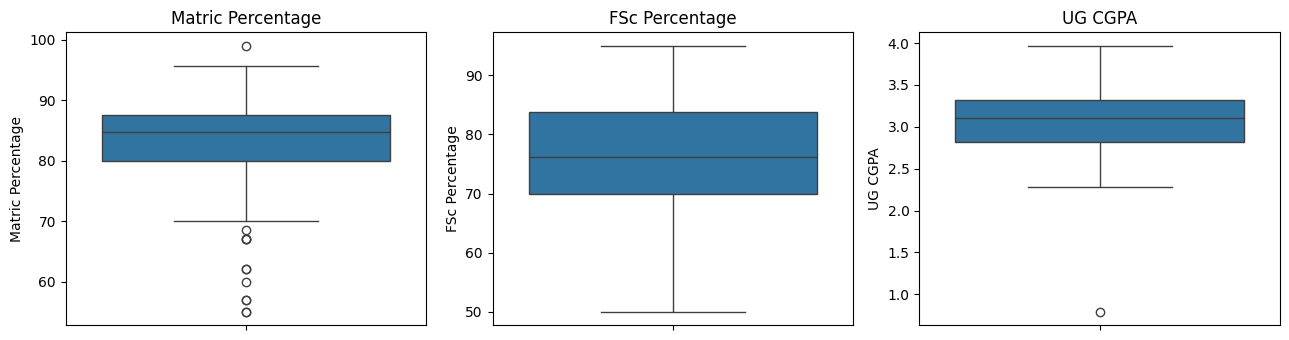

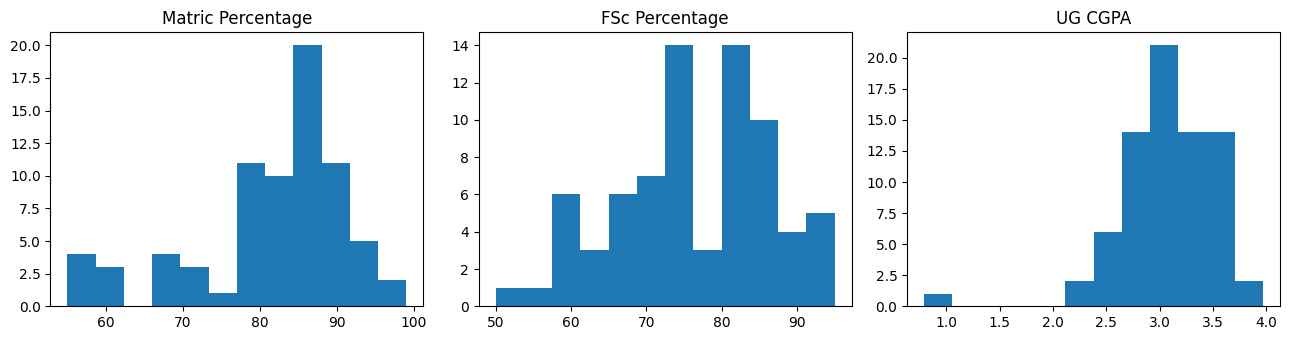

Pearson correlations (descriptive only):


,Matric Percentage,FSc Percentage,UG CGPA
Matric Percentage,1.000,0.659,0.265
FSc Percentage,0.659,1.000,0.248
UG CGPA,0.265,0.248,1.000


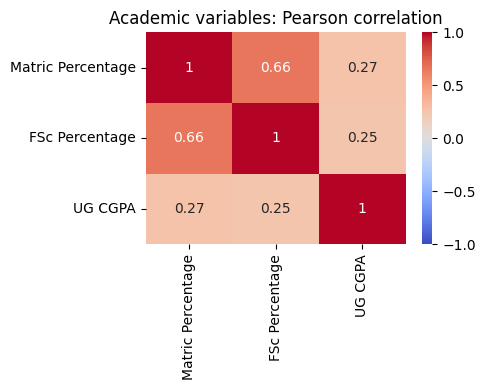

IQR flags are not automatically deleted: with this small dataset, valid extreme observations can be informative.


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
eda_cols = ["Matric Percentage", "FSc Percentage", "UG CGPA"]
print("Missing values after cleaning:")
display(model_df[feature_columns + ["UG CGPA"]].isna().sum().to_frame("Missing"))
outlier_rows=[]
for col in eda_cols:
    vals=model_df[col].dropna()
    q1,q3=vals.quantile([0.25,0.75]); iqr=q3-q1
    lower,upper=q1-1.5*iqr,q3+1.5*iqr
    count=int(((vals<lower)|(vals>upper)).sum())
    outlier_rows.append({"Variable":col,"Lower IQR bound":lower,"Upper IQR bound":upper,"Flagged outliers":count})
outlier_summary=pd.DataFrame(outlier_rows)
display(outlier_summary.round(3))
fig,axes=plt.subplots(1,3,figsize=(13,3.5))
for ax,col in zip(axes,eda_cols):
    sns.boxplot(y=model_df[col],ax=ax);ax.set_title(col)
plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,3,figsize=(13,3.5))
for ax,col in zip(axes,eda_cols):
    ax.hist(model_df[col].dropna(),bins=12);ax.set_title(col)
plt.tight_layout();plt.show()
correlations=model_df[eda_cols].corr()
print("Pearson correlations (descriptive only):")
display(correlations.round(3))
plt.figure(figsize=(5,4));sns.heatmap(correlations,annot=True,cmap="coolwarm",vmin=-1,vmax=1)
plt.title("Academic variables: Pearson correlation");plt.tight_layout();plt.show()
print("IQR flags are not automatically deleted: with this small dataset, valid extreme observations can be informative.")

## Step 5 — Train/test split and preprocessing
Use 80% training and 20% testing. Fit imputers, encoders, and scalers **only on training data** through pipelines to prevent leakage. The same held-out test set is used for every model.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
X = model_df[feature_columns].copy()
y_reg = model_df["UG CGPA"].copy()
y_cls = model_df["academic_risk"].copy()
X_train, X_test, y_train, y_test, y_train_cls, y_test_cls = train_test_split(
    X, y_reg, y_cls, test_size=0.20, random_state=42, stratify=y_cls
)
numeric_features = ["Matric Percentage", "FSc Percentage"]
categorical_features = [c for c in feature_columns if c not in numeric_features]
preprocessor = ColumnTransformer([
    ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]), numeric_features),
    ("categorical", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                              ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_features)
])
print("Train:", len(X_train), "Test:", len(X_test))
print("Training risk distribution:", y_train_cls.value_counts().to_dict())
print("Test risk distribution:", y_test_cls.value_counts().to_dict())

Train: 59 Test: 15
Training risk distribution: {0: 55, 1: 4}
Test risk distribution: {0: 14, 1: 1}


## Step 6 — Train Linear Regression, Ridge, and Lasso
Compare regression algorithms on the exact same test set. Tune regularization using cross-validation on the training set only.

In [9]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score
regression_models = {
    "Linear Regression (OLS)": Pipeline([("preprocess", preprocessor), ("model", LinearRegression())]),
    "Ridge Regression": Pipeline([("preprocess", preprocessor), ("model", Ridge(alpha=1.0))]),
    "Lasso Regression": Pipeline([("preprocess", preprocessor), ("model", Lasso(alpha=0.01, max_iter=20000))])
}
regression_rows = []
for name, pipe in regression_models.items():
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    regression_rows.append({"Model": name, "RMSE": np.sqrt(mean_squared_error(y_test, pred)), "R2": r2_score(y_test, pred)})
regression_comparison = pd.DataFrame(regression_rows)
display(regression_comparison.round(4))

,Model,RMSE,R2
0,Linear Regression (OLS),0.2465,0.5000
1,Ridge Regression,0.2558,0.4616
2,Lasso Regression,0.3029,0.2450


## Step 7 — Tune Ridge and Lasso regularization (5-fold CV)
Use cross-validation on training data. Small sample size means selected hyperparameters and test scores may be unstable.

In [10]:
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.base import clone

# Define a wider and more detailed range of alpha values
alpha_values = np.logspace(-4, 2, 25)

# Use reproducible 5-fold cross-validation
cv_strategy = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define model pipelines
ridge_pipeline = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("model", Ridge())
])

lasso_pipeline = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("model", Lasso(max_iter=50000))
])

# Perform hyperparameter tuning on training data only
ridge_cv = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid={"model__alpha": alpha_values},
    scoring="neg_mean_squared_error",
    cv=cv_strategy,
    n_jobs=1
)

lasso_cv = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid={"model__alpha": alpha_values},
    scoring="neg_mean_squared_error",
    cv=cv_strategy,
    n_jobs=1
)

# Store evaluation results
tuning_results = []

for name, search, baseline_name in [
    ("Ridge Tuned", ridge_cv, "Ridge Regression"),
    ("Lasso Tuned", lasso_cv, "Lasso Regression")
]:

    # Fit using training data only
    search.fit(X_train, y_train)

    # Predict on the unchanged test set
    predictions = search.predict(X_test)

    # Calculate test performance
    test_rmse = np.sqrt(
        mean_squared_error(y_test, predictions)
    )

    test_r2 = r2_score(y_test, predictions)

    # Extract best cross-validation RMSE
    cv_rmse = np.sqrt(-search.best_score_)

    # Retrieve the original baseline performance
    baseline_row = regression_comparison.loc[
        regression_comparison["Model"] == baseline_name
    ].iloc[0]

    tuning_results.append({
        "Model": name,
        "Best Alpha": search.best_params_["model__alpha"],
        "CV RMSE": cv_rmse,
        "Baseline Test RMSE": baseline_row["RMSE"],
        "Tuned Test RMSE": test_rmse,
        "Tuned Test R2": test_r2
    })

# Display results
tuning_comparison = pd.DataFrame(tuning_results)

print("STEP 7: RIDGE AND LASSO HYPERPARAMETER TUNING")
print("------------------------------------------------")

display(tuning_comparison.round(4))

# Identify whether tuning improved test RMSE
print("\nTEST PERFORMANCE COMPARISON")

for _, row in tuning_comparison.iterrows():

    if row["Tuned Test RMSE"] < row["Baseline Test RMSE"]:
        status = "Improved"
    elif row["Tuned Test RMSE"] > row["Baseline Test RMSE"]:
        status = "Decreased"
    else:
        status = "Unchanged"

    print(f"{row['Model']}: {status}")


STEP 7: RIDGE AND LASSO HYPERPARAMETER TUNING
------------------------------------------------


,Model,Best Alpha,CV RMSE,Baseline Test RMSE,Tuned Test RMSE,Tuned Test R2
0,Ridge Tuned,100.0,0.4668,0.2558,0.3077,0.2205
1,Lasso Tuned,0.1,0.4672,0.3029,0.3486,-0.0002



TEST PERFORMANCE COMPARISON
Ridge Tuned: Decreased
Lasso Tuned: Decreased


## Step 8 — Train baseline Logistic Regression and L1/L2 models
Classification predicts the **derived** academic-risk class. Class imbalance and the small number of positive test cases must be considered when interpreting recall.

In [11]:
import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    confusion_matrix,
    f1_score,
    balanced_accuracy_score
)

# Define Logistic Regression models with balanced class weights
classification_models = {
    "Logistic Regression (Standard)": Pipeline([
        ("preprocess", clone(preprocessor)),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=5000,
            random_state=42
        ))
    ]),

    "Logistic Regression (L1)": Pipeline([
        ("preprocess", clone(preprocessor)),
        ("model", LogisticRegression(
            penalty="l1",
            solver="liblinear",
            class_weight="balanced",
            max_iter=5000,
            random_state=42
        ))
    ]),

    "Logistic Regression (L2)": Pipeline([
        ("preprocess", clone(preprocessor)),
        ("model", LogisticRegression(
            penalty="l2",
            solver="liblinear",
            class_weight="balanced",
            max_iter=5000,
            random_state=42
        ))
    ])
}

# Define evaluation metrics
def classification_metrics(name, model, X_eval, y_eval):

    predictions = model.predict(X_eval)
    probabilities = model.predict_proba(X_eval)[:, 1]

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_eval, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_eval, predictions),
        "Precision": precision_score(
            y_eval, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_eval, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_eval, predictions, zero_division=0
        ),
        "ROC-AUC": (
            roc_auc_score(y_eval, probabilities)
            if len(np.unique(y_eval)) == 2
            else np.nan
        )
    }

# Train and evaluate all classification models
classification_rows = []

for name, pipeline in classification_models.items():

    # Fit only on training data
    pipeline.fit(X_train, y_train_cls)

    # Evaluate on the unchanged test set
    results = classification_metrics(
        name, pipeline, X_test, y_test_cls
    )

    classification_rows.append(results)

# Display model comparison
classification_comparison = pd.DataFrame(
    classification_rows
)

print("STEP 8: LOGISTIC REGRESSION MODEL COMPARISON")
print("------------------------------------------")

display(classification_comparison.round(4))

# Display confusion matrices for all models
print("\nCONFUSION MATRICES")

for name, pipeline in classification_models.items():

    predictions = pipeline.predict(X_test)

    cm = confusion_matrix(
        y_test_cls,
        predictions,
        labels=[0, 1]
    )

    print(f"\n{name}")
    print(cm)

# Display class distribution
print("\nTRAINING CLASS DISTRIBUTION")
print(y_train_cls.value_counts().sort_index())

print("\nTEST CLASS DISTRIBUTION")
print(y_test_cls.value_counts().sort_index())


STEP 8: LOGISTIC REGRESSION MODEL COMPARISON
------------------------------------------


,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression (Standard),0.8000,0.8929,0.25,1.0,0.4000,0.8571
1,Logistic Regression (L1),0.7333,0.8571,0.20,1.0,0.3333,0.7143
2,Logistic Regression (L2),0.8000,0.8929,0.25,1.0,0.4000,0.8571



CONFUSION MATRICES

Logistic Regression (Standard)
[[11  3]
 [ 0  1]]

Logistic Regression (L1)
[[10  4]
 [ 0  1]]

Logistic Regression (L2)
[[11  3]
 [ 0  1]]

TRAINING CLASS DISTRIBUTION
academic_risk
0    55
1     4
Name: count, dtype: int64

TEST CLASS DISTRIBUTION
academic_risk
0    14
1     1
Name: count, dtype: int64


## Step 9 — Tune L1 and L2 Logistic Regression with cross-validation
Use stratified 5-fold cross-validation where possible. Select the best C using ROC-AUC, then evaluate once on the unchanged test set.

In [12]:
import numpy as np
import pandas as pd

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import confusion_matrix

# Determine the number of minority-class samples
min_class = int(y_train_cls.value_counts().min())

if min_class < 2:
    raise ValueError(
        "Too few minority-class training examples for cross-validation."
    )

# Use as many stratified folds as the minority class permits
cv_cls = StratifiedKFold(
    n_splits=min(5, min_class),
    shuffle=True,
    random_state=42
)

# Define regularization strength values
c_values = [0.001, 0.01, 0.1, 1, 10, 100]

classification_tuned = {}
tuning_summary = []

# Tune L1 and L2 models separately
for penalty in ["l1", "l2"]:

    pipeline = Pipeline([
        ("preprocess", clone(preprocessor)),
        ("model", LogisticRegression(
            penalty=penalty,
            solver="liblinear",
            class_weight="balanced",
            max_iter=5000,
            random_state=42
        ))
    ])

    # Tune C using training data only
    search = GridSearchCV(
        estimator=pipeline,
        param_grid={"model__C": c_values},
        cv=cv_cls,
        scoring="roc_auc",
        n_jobs=1
    )

    search.fit(X_train, y_train_cls)

    # Store the best trained model
    classification_tuned[penalty] = search.best_estimator_

    tuning_summary.append({
        "Model": f"Logistic Regression ({penalty.upper()} Tuned)",
        "Best C": search.best_params_["model__C"],
        "CV ROC-AUC": search.best_score_
    })

# Display cross-validation results
print("STEP 9: LOGISTIC REGRESSION HYPERPARAMETER TUNING")
print("------------------------------------------------")

display(pd.DataFrame(tuning_summary).round(4))

# Evaluate tuned models on the unchanged test set
tuned_results = pd.DataFrame([
    classification_metrics(
        "Logistic Regression (L1 Tuned)",
        classification_tuned["l1"],
        X_test,
        y_test_cls
    ),
    classification_metrics(
        "Logistic Regression (L2 Tuned)",
        classification_tuned["l2"],
        X_test,
        y_test_cls
    )
])

print("\nTUNED MODEL TEST PERFORMANCE")
display(tuned_results.round(4))

# Display confusion matrices
print("\nCONFUSION MATRICES")

for penalty in ["l1", "l2"]:

    predictions = classification_tuned[penalty].predict(X_test)

    print(f"\n{penalty.upper()} Tuned:")
    print(confusion_matrix(
        y_test_cls,
        predictions,
        labels=[0, 1]
    ))


STEP 9: LOGISTIC REGRESSION HYPERPARAMETER TUNING
------------------------------------------------


,Model,Best C,CV ROC-AUC
0,Logistic Regression (L1 Tuned),100,0.5261
1,Logistic Regression (L2 Tuned),100,0.4712



TUNED MODEL TEST PERFORMANCE


,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression (L1 Tuned),0.9333,0.9643,0.5,1.0,0.6667,0.9286
1,Logistic Regression (L2 Tuned),0.9333,0.9643,0.5,1.0,0.6667,0.9286



CONFUSION MATRICES

L1 Tuned:
[[13  1]
 [ 0  1]]

L2 Tuned:
[[13  1]
 [ 0  1]]


## Step 10 — Logistic Regression from scratch: sigmoid, cost, and gradient descent
Build a manual implementation using the training-only preprocessing pipeline. No `sklearn.LogisticRegression` is used for this model.

In [13]:
# Transform training and test data using a preprocessor fitted on training only.
from sklearn.base import clone
scratch_preprocessor = clone(preprocessor)
X_train_scratch = scratch_preprocessor.fit_transform(X_train)
X_test_scratch = scratch_preprocessor.transform(X_test)
if hasattr(X_train_scratch, "toarray"):
    X_train_scratch = X_train_scratch.toarray()
if hasattr(X_test_scratch, "toarray"):
    X_test_scratch = X_test_scratch.toarray()
y_train_scratch = y_train_cls.to_numpy(dtype=float)
y_test_scratch = y_test_cls.to_numpy(dtype=int)
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))
def compute_cost(y, probabilities):
    p = np.clip(probabilities, 1e-15, 1 - 1e-15)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
def gradient_descent(X_data, y_data, learning_rate=0.01, iterations=10000):
    m, n = X_data.shape
    weights, bias, history = np.zeros(n), 0.0, []
    for iteration in range(iterations):
        probabilities = sigmoid(X_data @ weights + bias)
        weights -= learning_rate * (X_data.T @ (probabilities - y_data)) / m
        bias -= learning_rate * np.mean(probabilities - y_data)
        if iteration % 100 == 0 or iteration == iterations - 1:
            history.append(compute_cost(y_data, sigmoid(X_data @ weights + bias)))
    return weights, bias, history
scratch_weights, scratch_bias, scratch_costs = gradient_descent(X_train_scratch, y_train_scratch)
print("Training samples:", X_train_scratch.shape[0], "| Features:", X_train_scratch.shape[1])
print("Initial cost:", round(scratch_costs[0], 4), "| Final cost:", round(scratch_costs[-1], 4))

Training samples: 59 | Features: 15
Initial cost: 0.689 | Final cost: 0.1796


## Step 11 — Evaluate scratch Logistic Regression
Compare scratch performance with Scikit-learn on the same test set and decision threshold.

STEP 11: WEIGHTED SCRATCH LOGISTIC REGRESSION
---------------------------------------------


,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression From Scratch (Weighted),0.8,0.4286,0.0,0.0,0.0,0.8571



Scratch Confusion Matrix:
[[12  2]
 [ 1  0]]

Training Cost:
Initial: 0.6925
Final: 0.3178


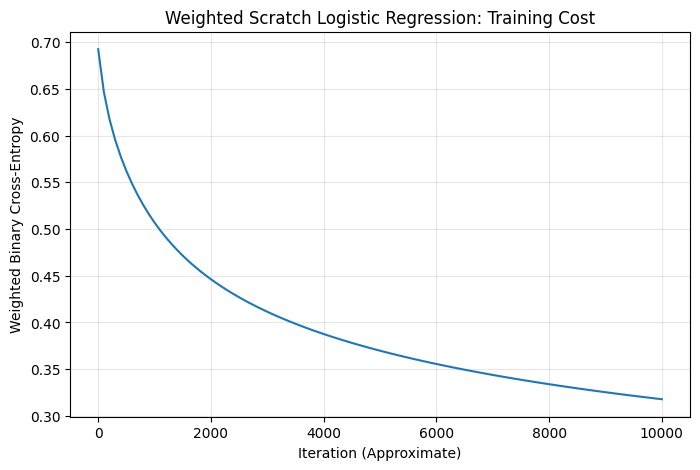

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    confusion_matrix
)

# Calculate class weights using training labels only
n_samples = len(y_train_scratch)
n_positive = np.sum(y_train_scratch == 1)
n_negative = np.sum(y_train_scratch == 0)

weight_positive = n_samples / (2 * n_positive)
weight_negative = n_samples / (2 * n_negative)

sample_weights = np.where(
    y_train_scratch == 1,
    weight_positive,
    weight_negative
)

# Define weighted binary cross-entropy
def weighted_cost(y, probabilities, weights):
    p = np.clip(probabilities, 1e-15, 1 - 1e-15)
    losses = -(y * np.log(p) + (1 - y) * np.log(1 - p))
    return np.sum(weights * losses) / np.sum(weights)

# Implement class-weighted gradient descent from scratch
def weighted_gradient_descent(
    X_data,
    y_data,
    sample_weights,
    learning_rate=0.01,
    iterations=10000
):
    m, n = X_data.shape

    weights = np.zeros(n)
    bias = 0.0
    cost_history = []

    for iteration in range(iterations):

        probabilities = sigmoid(X_data @ weights + bias)

        errors = (probabilities - y_data) * sample_weights

        gradient_w = (X_data.T @ errors) / np.sum(sample_weights)
        gradient_b = np.sum(errors) / np.sum(sample_weights)

        weights -= learning_rate * gradient_w
        bias -= learning_rate * gradient_b

        if iteration % 100 == 0 or iteration == iterations - 1:
            updated_probs = sigmoid(X_data @ weights + bias)

            cost_history.append(
                weighted_cost(
                    y_data,
                    updated_probs,
                    sample_weights
                )
            )

    return weights, bias, cost_history

# Train the weighted scratch model
weighted_scratch_weights, weighted_scratch_bias, weighted_costs = (
    weighted_gradient_descent(
        X_train_scratch,
        y_train_scratch,
        sample_weights
    )
)

# Predict on the unchanged test set
scratch_probabilities = sigmoid(
    X_test_scratch @ weighted_scratch_weights + weighted_scratch_bias
)

scratch_predictions = (
    scratch_probabilities >= 0.5
).astype(int)

# Evaluate classification performance
scratch_result = {
    "Model": "Logistic Regression From Scratch (Weighted)",
    "Accuracy": accuracy_score(
        y_test_scratch, scratch_predictions
    ),
    "Balanced Accuracy": balanced_accuracy_score(
        y_test_scratch, scratch_predictions
    ),
    "Precision": precision_score(
        y_test_scratch, scratch_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test_scratch, scratch_predictions, zero_division=0
    ),
    "F1-Score": f1_score(
        y_test_scratch, scratch_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test_scratch, scratch_probabilities
    )
}

print("STEP 11: WEIGHTED SCRATCH LOGISTIC REGRESSION")
print("---------------------------------------------")

display(pd.DataFrame([scratch_result]).round(4))

print("\nScratch Confusion Matrix:")
print(confusion_matrix(
    y_test_scratch,
    scratch_predictions,
    labels=[0, 1]
))

print("\nTraining Cost:")
print("Initial:", round(weighted_costs[0], 4))
print("Final:", round(weighted_costs[-1], 4))

# Plot training cost
plt.figure(figsize=(8, 5))
plt.plot(
    np.arange(len(weighted_costs)) * 100,
    weighted_costs
)

plt.title("Weighted Scratch Logistic Regression: Training Cost")
plt.xlabel("Iteration (Approximate)")
plt.ylabel("Weighted Binary Cross-Entropy")
plt.grid(alpha=0.3)
plt.show()


## Step 11A — Inspect scratch predictions

In [24]:
scratch_diagnostics = pd.DataFrame({
    "Actual Risk": y_test_scratch,
    "Predicted Probability": scratch_probabilities,
    "Predicted Risk": scratch_predictions
})

scratch_diagnostics["Correct"] = (
    scratch_diagnostics["Actual Risk"]
    == scratch_diagnostics["Predicted Risk"]
)

display(
    scratch_diagnostics.sort_values(
        "Predicted Probability",
        ascending=False
    ).round(4)
)

print("\nActual at-risk student's prediction:")
display(
    scratch_diagnostics[
        scratch_diagnostics["Actual Risk"] == 1
    ].round(4)
)

,Actual Risk,Predicted Probability,Predicted Risk,Correct
1,0,0.9620,1,False
10,0,0.5868,1,False
13,1,0.4541,0,False
11,0,0.4173,0,True
6,0,0.3565,0,True
0,0,0.3375,0,True
9,0,0.2322,0,True
8,0,0.1273,0,True
2,0,0.0888,0,True
4,0,0.0650,0,True



Actual at-risk student's prediction:


,Actual Risk,Predicted Probability,Predicted Risk,Correct
13,1,0.4541,0,False


## Step 12 — Ridge Regression data truncation
Train with 100%, 75%, and 50% of the original training set. Never truncate the held-out test set.

In [15]:
ridge_truncation_rows = []
for fraction in [1.0, 0.75, 0.50]:
    if fraction == 1:
        X_sub, y_sub = X_train, y_train
    else:
        X_sub, _, y_sub, _ = train_test_split(X_train, y_train, train_size=fraction, random_state=42)
    pipe = Pipeline([("preprocess", clone(preprocessor)), ("model", Ridge(alpha=1.0))])
    pipe.fit(X_sub, y_sub)
    pred = pipe.predict(X_test)
    ridge_truncation_rows.append({"Training Data": f"{fraction:.0%}", "Training Samples": len(X_sub),
                                  "RMSE": np.sqrt(mean_squared_error(y_test, pred)), "R2": r2_score(y_test, pred)})
ridge_truncation_df = pd.DataFrame(ridge_truncation_rows)
display(ridge_truncation_df.round(4))

,Training Data,Training Samples,RMSE,R2
0,100%,59,0.2558,0.4616
1,75%,44,0.2011,0.6671
2,50%,29,0.2479,0.4942


##Step 12A — Repeated Ridge Regression Data Truncation

In [25]:
# Repeated training-data truncation
repeated_results = []

for fraction in [1.0, 0.75, 0.50]:
    for seed in range(20):

        if fraction == 1.0:
            X_sub, y_sub = X_train, y_train
        else:
            X_sub, _, y_sub, _ = train_test_split(
                X_train,
                y_train,
                train_size=fraction,
                random_state=seed
            )

        model = Pipeline([
            ("preprocess", clone(preprocessor)),
            ("model", Ridge(alpha=1.0))
        ])

        model.fit(X_sub, y_sub)
        predictions = model.predict(X_test)

        repeated_results.append({
            "Training Data": f"{fraction:.0%}",
            "Seed": seed,
            "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
            "R2": r2_score(y_test, predictions)
        })

repeated_df = pd.DataFrame(repeated_results)

display(
    repeated_df.groupby("Training Data")[
        ["RMSE", "R2"]
    ].agg(["mean", "std"]).round(4)
)

RMSE              R2        
                 mean     std    mean     std
Training Data                                
100%           0.2558  0.0000  0.4616  0.0000
50%            0.3380  0.0793  0.0104  0.4413
75%            0.2929  0.0392  0.2818  0.1865

## Step 13 — Logistic Regression data truncation
Use stratified subsampling so each training subset retains approximately the same class distribution.

In [16]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone

# Store truncation results
log_truncation_rows = []

# Evaluate different training data fractions
for fraction in [1.0, 0.75, 0.50]:

    # Select training subset
    if fraction == 1.0:
        X_sub = X_train.copy()
        y_sub = y_train_cls.copy()

    else:
        X_sub, _, y_sub, _ = train_test_split(
            X_train,
            y_train_cls,
            train_size=fraction,
            stratify=y_train_cls,
            random_state=42
        )

    # Create Logistic Regression pipeline
    pipe = Pipeline([
        ("preprocess", clone(preprocessor)),
        ("model", LogisticRegression(
            penalty="l2",
            solver="liblinear",
            class_weight="balanced",
            max_iter=5000,
            random_state=42
        ))
    ])

    # Train on the selected subset only
    pipe.fit(X_sub, y_sub)

    # Evaluate on the unchanged test set
    row = classification_metrics(
        f"{fraction:.0%}",
        pipe,
        X_test,
        y_test_cls
    )

    # Add training subset information
    row["Training Samples"] = len(X_sub)
    row["Risk Students in Train"] = int(y_sub.sum())

    log_truncation_rows.append(row)

# Create comparison DataFrame
log_truncation_df = pd.DataFrame(log_truncation_rows)

# Reorder columns
log_truncation_df = log_truncation_df[
    [
        "Model",
        "Training Samples",
        "Risk Students in Train",
        "Accuracy",
        "Balanced Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ]
]

print("STEP 13: LOGISTIC REGRESSION DATA TRUNCATION")
print("--------------------------------------------")

display(log_truncation_df.round(4))


STEP 13: LOGISTIC REGRESSION DATA TRUNCATION
--------------------------------------------


,Model,Training Samples,Risk Students in Train,Accuracy,Balanced Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,100%,59,4,0.8000,0.8929,0.2500,1.0,0.4000,0.8571
1,75%,44,3,0.7333,0.8571,0.2000,1.0,0.3333,0.7143
2,50%,29,2,0.6667,0.8214,0.1667,1.0,0.2857,0.7143


## Step 14 — Final model comparison tables and charts
Summarize all model families without mixing regression and classification metrics.

FINAL REGRESSION COMPARISON


,Model,RMSE,R2
0,Linear Regression (OLS),0.2465,0.5000
1,Ridge Regression,0.2558,0.4616
2,Lasso Regression,0.3029,0.2450
3,Ridge (Tuned),0.3077,0.2205
4,Lasso (Tuned),0.3486,-0.0002



FINAL CLASSIFICATION COMPARISON


,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression (Standard),0.8000,0.8929,0.25,1.0,0.4000,0.8571
1,Logistic Regression (L1),0.7333,0.8571,0.20,1.0,0.3333,0.7143
2,Logistic Regression (L2),0.8000,0.8929,0.25,1.0,0.4000,0.8571
3,Logistic Regression (L1 Tuned),0.9333,0.9643,0.50,1.0,0.6667,0.9286
4,Logistic Regression (L2 Tuned),0.9333,0.9643,0.50,1.0,0.6667,0.9286
5,Logistic Regression From Scratch (Unweighted),0.9333,0.5000,0.00,0.0,0.0000,0.8571
6,Logistic Regression From Scratch (Weighted),0.8000,0.4286,0.00,0.0,0.0000,0.8571


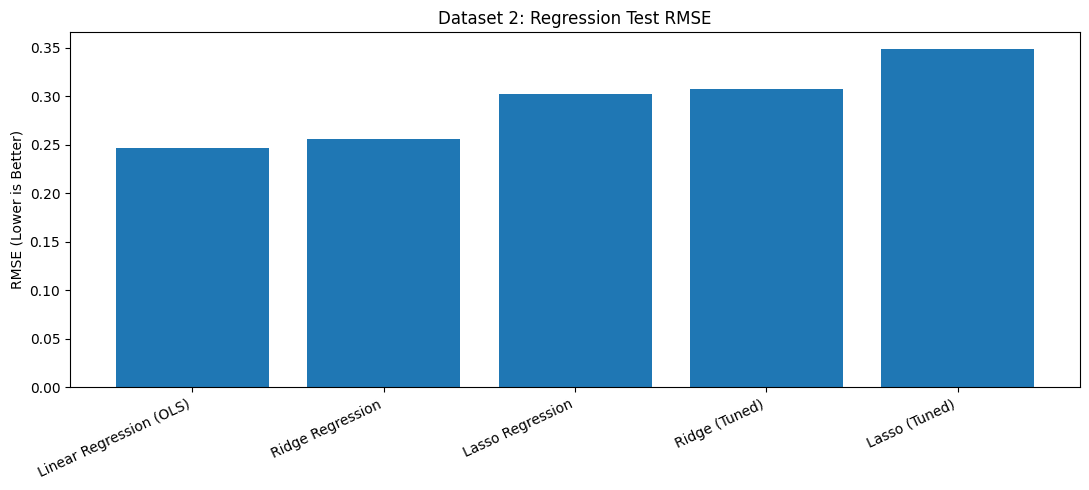

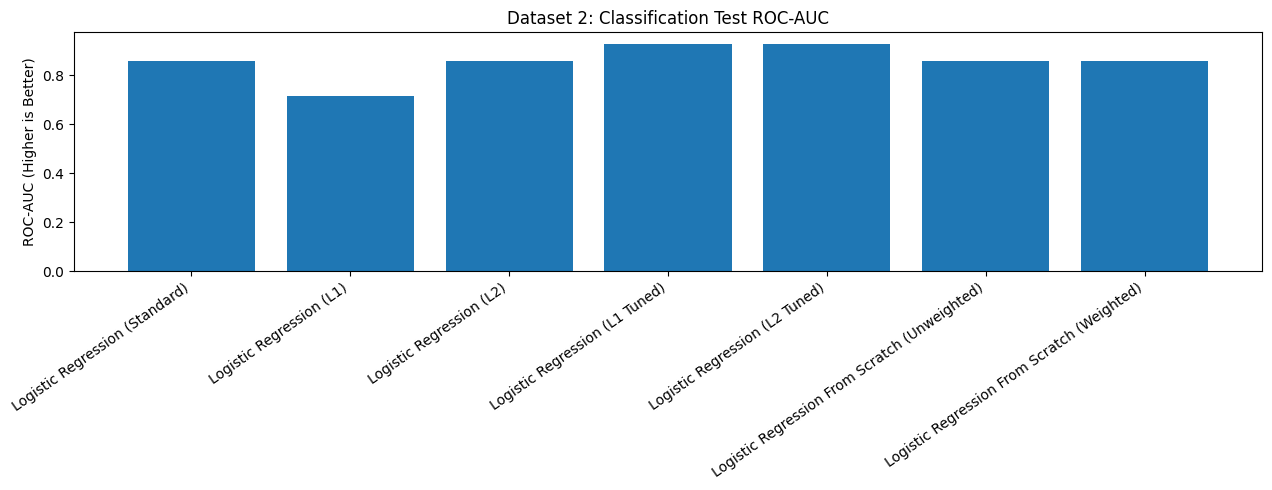

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score
)

# -------------------------------------------
# Part 1: Final Regression Comparison
# -------------------------------------------

regression_tuned_rows = []

for name, search in [
    ("Ridge (Tuned)", ridge_cv),
    ("Lasso (Tuned)", lasso_cv)
]:
    predictions = search.predict(X_test)

    regression_tuned_rows.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

regression_final = pd.concat(
    [
        regression_comparison,
        pd.DataFrame(regression_tuned_rows)
    ],
    ignore_index=True
)

# -------------------------------------------
# Part 2: Unweighted Scratch Logistic Regression
# -------------------------------------------

# Use the original weights learned in Step 10
unweighted_probabilities = sigmoid(
    X_test_scratch @ scratch_weights + scratch_bias
)

unweighted_predictions = (
    unweighted_probabilities >= 0.5
).astype(int)

unweighted_scratch_result = {
    "Model": "Logistic Regression From Scratch (Unweighted)",
    "Accuracy": accuracy_score(
        y_test_scratch, unweighted_predictions
    ),
    "Balanced Accuracy": balanced_accuracy_score(
        y_test_scratch, unweighted_predictions
    ),
    "Precision": precision_score(
        y_test_scratch, unweighted_predictions,
        zero_division=0
    ),
    "Recall": recall_score(
        y_test_scratch, unweighted_predictions,
        zero_division=0
    ),
    "F1-Score": f1_score(
        y_test_scratch, unweighted_predictions,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test_scratch, unweighted_probabilities
    )
}

# -------------------------------------------
# Part 3: Weighted Scratch Logistic Regression
# -------------------------------------------

# Use the weighted weights learned in Step 11
weighted_probabilities = sigmoid(
    X_test_scratch @ weighted_scratch_weights
    + weighted_scratch_bias
)

weighted_predictions = (
    weighted_probabilities >= 0.5
).astype(int)

weighted_scratch_result = {
    "Model": "Logistic Regression From Scratch (Weighted)",
    "Accuracy": accuracy_score(
        y_test_scratch, weighted_predictions
    ),
    "Balanced Accuracy": balanced_accuracy_score(
        y_test_scratch, weighted_predictions
    ),
    "Precision": precision_score(
        y_test_scratch, weighted_predictions,
        zero_division=0
    ),
    "Recall": recall_score(
        y_test_scratch, weighted_predictions,
        zero_division=0
    ),
    "F1-Score": f1_score(
        y_test_scratch, weighted_predictions,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test_scratch, weighted_probabilities
    )
}

# -------------------------------------------
# Part 4: Final Classification Comparison
# -------------------------------------------

classification_final = pd.concat(
    [
        classification_comparison,
        tuned_results,
        pd.DataFrame([
            unweighted_scratch_result,
            weighted_scratch_result
        ])
    ],
    ignore_index=True
)

# Display final comparison tables
print("FINAL REGRESSION COMPARISON")
display(regression_final.round(4))

print("\nFINAL CLASSIFICATION COMPARISON")
display(classification_final.round(4))

# -------------------------------------------
# Part 5: Regression RMSE Chart
# -------------------------------------------

plt.figure(figsize=(11, 5))

plt.bar(
    regression_final["Model"],
    regression_final["RMSE"]
)

plt.title("Dataset 2: Regression Test RMSE")
plt.ylabel("RMSE (Lower is Better)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

# -------------------------------------------
# Part 6: Classification ROC-AUC Chart
# -------------------------------------------

plt.figure(figsize=(13, 5))

plt.bar(
    classification_final["Model"],
    classification_final["ROC-AUC"]
)

plt.title("Dataset 2: Classification Test ROC-AUC")
plt.ylabel("ROC-AUC (Higher is Better)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


## Step 15 — Final verification and limitations
Verify that all required result tables exist. A small, self-reported dataset cannot establish robust predictive accuracy. Classification is a **CGPA-threshold proxy**, not real dropout prediction. MS results and MS-admission preparation are excluded from predictors to avoid post-outcome leakage.

In [18]:
import pandas as pd

# Verify required result tables
required = {
    "Regression comparison": "regression_final",
    "Classification comparison": "classification_final",
    "Ridge truncation": "ridge_truncation_df",
    "Logistic truncation": "log_truncation_df",
    "Scratch results": "scratch_result"
}

print("FINAL VERIFICATION")
print("-" * 45)

for title, name in required.items():
    status = "[PASS]" if name in globals() else "[MISSING]"
    print(f"{status} {title}")

# Display dataset summary
print("\nDATASET SUMMARY")
print("-" * 45)
print("Original records:", len(df_raw))
print("Valid target records:", len(model_df))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

# Display academic risk distribution
print("\nACADEMIC RISK DISTRIBUTION")
print("-" * 45)

risk_counts = model_df["academic_risk"].value_counts()

risk_summary = pd.DataFrame({
    "Risk Category": ["Not At Risk (0)", "At Risk (1)"],
    "Students": [
        risk_counts.get(0, 0),
        risk_counts.get(1, 0)
    ]
})

risk_summary["Percentage"] = (
    risk_summary["Students"] / len(model_df) * 100
)

display(risk_summary.round(2))

# Identify best observed regression model
best_regression = regression_final.loc[
    regression_final["RMSE"].idxmin()
]

print("\nBEST OBSERVED REGRESSION MODEL")
print("-" * 45)
print("Model:", best_regression["Model"])
print("Test RMSE:", round(best_regression["RMSE"], 4))
print("Test R2:", round(best_regression["R2"], 4))

# Identify best observed classification model by F1-score
best_classification = classification_final.loc[
    classification_final["F1-Score"].idxmax()
]

print("\nBEST OBSERVED CLASSIFICATION MODEL")
print("-" * 45)
print("Model:", best_classification["Model"])
print("Test Accuracy:", round(best_classification["Accuracy"], 4))
print("Test Precision:", round(best_classification["Precision"], 4))
print("Test Recall:", round(best_classification["Recall"], 4))
print("Test F1-Score:", round(best_classification["F1-Score"], 4))
print("Test ROC-AUC:", round(best_classification["ROC-AUC"], 4))

# Display study limitations
print("\nIMPORTANT LIMITATIONS")
print("-" * 45)
print("1. Dataset contains only 74 valid target records.")
print("2. Only 5 students belong to the At Risk class.")
print("3. The test set contains only 1 At Risk student.")
print("4. Academic risk is defined using UG CGPA < 2.5.")
print("5. Academic risk is a derived proxy, not observed dropout.")
print("6. Model performance may be unstable due to the small dataset.")
print("7. MS outcomes and MS-admission preparation were excluded from predictors.")
print("8. Best model rankings describe this test split only.")


FINAL VERIFICATION
---------------------------------------------
[PASS] Regression comparison
[PASS] Classification comparison
[PASS] Ridge truncation
[PASS] Logistic truncation
[PASS] Scratch results

DATASET SUMMARY
---------------------------------------------
Original records: 78
Valid target records: 74
Training records: 59
Testing records: 15

ACADEMIC RISK DISTRIBUTION
---------------------------------------------


,Risk Category,Students,Percentage
0,Not At Risk (0),69,93.24
1,At Risk (1),5,6.76



BEST OBSERVED REGRESSION MODEL
---------------------------------------------
Model: Linear Regression (OLS)
Test RMSE: 0.2465
Test R2: 0.5

BEST OBSERVED CLASSIFICATION MODEL
---------------------------------------------
Model: Logistic Regression (L1 Tuned)
Test Accuracy: 0.9333
Test Precision: 0.5
Test Recall: 1.0
Test F1-Score: 0.6667
Test ROC-AUC: 0.9286

IMPORTANT LIMITATIONS
---------------------------------------------
1. Dataset contains only 74 valid target records.
2. Only 5 students belong to the At Risk class.
3. The test set contains only 1 At Risk student.
4. Academic risk is defined using UG CGPA < 2.5.
5. Academic risk is a derived proxy, not observed dropout.
6. Model performance may be unstable due to the small dataset.
7. MS outcomes and MS-admission preparation were excluded from predictors.
8. Best model rankings describe this test split only.


## Step 16 — Test Evaluation: Actual vs Predicted

In [19]:

# Step 16: Evaluate predictions on the held-out test set

import numpy as np
import pandas as pd

# Use the trained OLS regression model
reg_model = regression_models["Linear Regression (OLS)"]

# Predict UG CGPA
predicted_cgpa = reg_model.predict(X_test)

# Use the tuned L1 and L2 classification models
l1_model = classification_tuned["l1"]
l2_model = classification_tuned["l2"]

# Predict academic risk
predicted_risk_l1 = l1_model.predict(X_test)
predicted_risk_l2 = l2_model.predict(X_test)

# Get risk probabilities
risk_probability_l1 = l1_model.predict_proba(X_test)[:, 1]
risk_probability_l2 = l2_model.predict_proba(X_test)[:, 1]

# Create student-level evaluation table
test_evaluation = pd.DataFrame({
    "Actual UG CGPA": np.asarray(y_test, dtype=float),
    "Predicted UG CGPA": predicted_cgpa,
    "Actual Risk": np.asarray(y_test_cls, dtype=int),
    "Predicted Risk L1": predicted_risk_l1,
    "Predicted Risk L2": predicted_risk_l2,
    "Risk Probability L1": risk_probability_l1,
    "Risk Probability L2": risk_probability_l2
})

# Calculate absolute CGPA prediction error
test_evaluation["CGPA Absolute Error"] = abs(
    test_evaluation["Actual UG CGPA"]
    - test_evaluation["Predicted UG CGPA"]
)

# Check whether classification predictions are correct
test_evaluation["L1 Correct"] = (
    test_evaluation["Actual Risk"]
    == test_evaluation["Predicted Risk L1"]
)

test_evaluation["L2 Correct"] = (
    test_evaluation["Actual Risk"]
    == test_evaluation["Predicted Risk L2"]
)

# Add student identifiers
test_evaluation.insert(
    0,
    "Test Student",
    np.arange(1, len(test_evaluation) + 1)
)

print("STEP 16: ACTUAL VS PREDICTED RESULTS")
print("-" * 50)

display(test_evaluation.round(4))

# Summarize test predictions
print("\nREGRESSION EVALUATION")
print("Mean Absolute CGPA Error:",
      round(test_evaluation["CGPA Absolute Error"].mean(), 4))

print("\nCLASSIFICATION EVALUATION")
print("L1 Correct Predictions:",
      int(test_evaluation["L1 Correct"].sum()),
      "/", len(test_evaluation))

print("L2 Correct Predictions:",
      int(test_evaluation["L2 Correct"].sum()),
      "/", len(test_evaluation))

print("\nIncorrect L1 Predictions:")
display(
    test_evaluation.loc[
        ~test_evaluation["L1 Correct"],
        ["Test Student", "Actual Risk",
         "Predicted Risk L1", "Risk Probability L1"]
    ].round(4)
)


STEP 16: ACTUAL VS PREDICTED RESULTS
--------------------------------------------------


,Test Student,Actual UG CGPA,Predicted UG CGPA,Actual Risk,Predicted Risk L1,Predicted Risk L2,Risk Probability L1,Risk Probability L2,CGPA Absolute Error,L1 Correct,L2 Correct
0,1,2.76,2.8338,0,0,0,0.0000,0.0216,0.0738,True,True
1,2,3.13,2.5368,0,1,1,1.0000,0.9997,0.5932,False,False
2,3,3.07,3.0015,0,0,0,0.0000,0.0002,0.0685,True,True
3,4,3.49,3.2770,0,0,0,0.0000,0.0000,0.2130,True,True
4,5,3.30,3.1593,0,0,0,0.0000,0.0007,0.1407,True,True
5,6,3.59,3.3465,0,0,0,0.0000,0.0000,0.2435,True,True
6,7,3.30,3.2212,0,0,0,0.0000,0.0003,0.0788,True,True
7,8,3.53,3.2247,0,0,0,0.0000,0.0000,0.3053,True,True
8,9,2.62,2.8193,0,0,0,0.0002,0.0068,0.1993,True,True
9,10,2.90,3.0785,0,0,0,0.0000,0.0112,0.1785,True,True



REGRESSION EVALUATION
Mean Absolute CGPA Error: 0.2006

CLASSIFICATION EVALUATION
L1 Correct Predictions: 14 / 15
L2 Correct Predictions: 14 / 15

Incorrect L1 Predictions:


,Test Student,Actual Risk,Predicted Risk L1,Risk Probability L1
1,2,0,1,1.0


## Report notes
- **Target:** `UG CGPA` for regression; a derived threshold label for classification.
- **Features:** Gender, province, parental education group, Matric percentage, and FSc percentage.
- **Leakage control:** Timestamp, university name, MS CGPA, MS SGPA, MS semester, completed MS credit hours, and MS admission preparation were not used as predictors.
- **Data quality:** Fraction-format percentages are normalized; invalid target rows removed; missing feature values imputed from training data only.
- **Limitations:** Small sample, self-reported entries, noisy categorical labels, class imbalance, and unstable hold-out estimates. Report the actual results after executing all cells.

## Step 17 — Regression Coefficients and Regularization Interpretation
All coefficients are compared using the same encoded feature ordering. Numerical coefficients are per one training-set standard deviation; full one-hot dummy coefficients depend on coding and should not be interpreted causally.

Regression coefficients:


,Feature,OLS,Ridge baseline,Lasso baseline,Ridge tuned,Lasso tuned
0,numeric__Matric Percentage,0.1203,0.0995,0.0648,0.0283,0.0
1,numeric__FSc Percentage,0.0154,0.0193,0.0211,0.0194,0.0
2,categorical__What is your Gender_Female,0.0278,0.0266,0.0005,0.0113,0.0
3,categorical__What is your Gender_Male,-0.0278,-0.0266,-0.0000,-0.0113,-0.0
4,categorical__Which Province do you belong to_GB,-0.3321,-0.1681,-0.0000,-0.0033,-0.0
5,categorical__Which Province do you belong to_KPK,-0.1783,-0.1791,-0.2124,-0.0248,-0.0
6,categorical__Which Province do you belong to_K...,0.4265,0.2787,0.0375,0.0060,0.0
7,categorical__Which Province do you belong to_P...,0.0455,0.0391,0.0000,0.0176,0.0
8,categorical__Which Province do you belong to_S...,0.0384,0.0295,0.0000,0.0045,0.0
9,categorical__Parental Education Group_Bachelors,-0.0256,-0.0297,-0.0000,-0.0036,-0.0


Top positive OLS:


,Feature,OLS
6,categorical__Which Province do you belong to_K...,0.4265
13,categorical__Parental Education Group_School o...,0.2628
0,numeric__Matric Percentage,0.1203
10,categorical__Parental Education Group_Intermed...,0.0969
7,categorical__Which Province do you belong to_P...,0.0455


Top negative OLS:


,Feature,OLS
4,categorical__Which Province do you belong to_GB,-0.3321
14,categorical__Parental Education Group_Unknown,-0.2782
5,categorical__Which Province do you belong to_KPK,-0.1783
11,categorical__Parental Education Group_Masters,-0.0313
3,categorical__What is your Gender_Male,-0.0278


Near-zero coefficients:
OLS 0
Ridge baseline 0
Lasso baseline 8
Ridge tuned 0
Lasso tuned 15


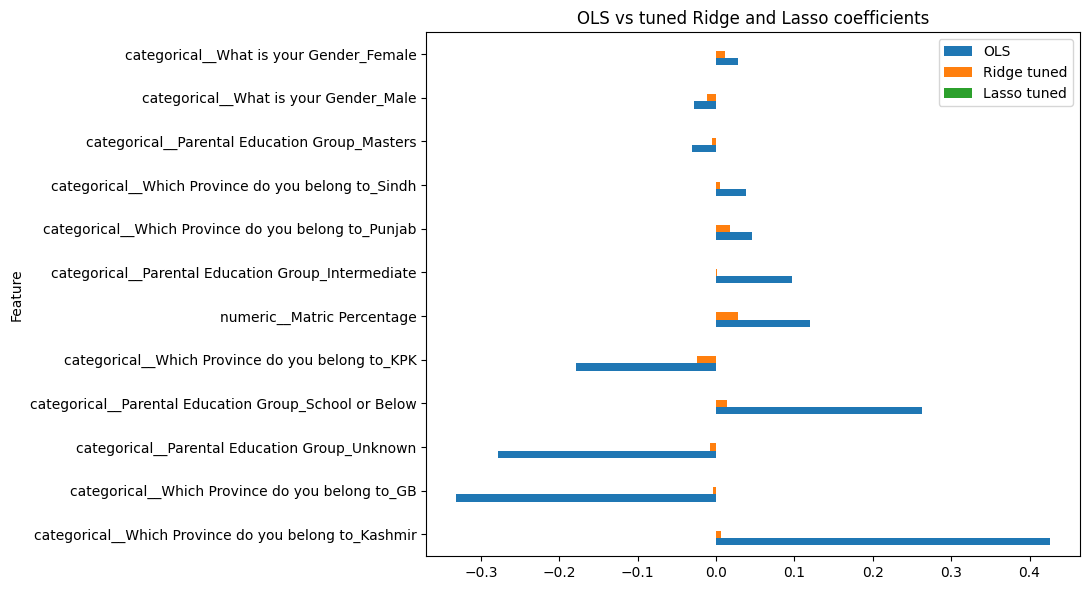

In [20]:
from sklearn.base import clone
reg_candidates = {
    "OLS": regression_models["Linear Regression (OLS)"],
    "Ridge baseline": regression_models["Ridge Regression"],
    "Lasso baseline": regression_models["Lasso Regression"],
    "Ridge tuned": ridge_cv.best_estimator_,
    "Lasso tuned": lasso_cv.best_estimator_,
}
features_reg = reg_candidates["OLS"].named_steps["preprocess"].get_feature_names_out()
regression_coefficients = pd.DataFrame({"Feature": features_reg})
for name, model in reg_candidates.items():
    regression_coefficients[name] = model.named_steps["model"].coef_
print("Regression coefficients:");display(regression_coefficients.round(4))
print("Top positive OLS:");display(regression_coefficients.nlargest(5,"OLS")[["Feature","OLS"]].round(4))
print("Top negative OLS:");display(regression_coefficients.nsmallest(5,"OLS")[["Feature","OLS"]].round(4))
print("Near-zero coefficients:")
for name in reg_candidates:
    print(name, int(np.isclose(regression_coefficients[name],0,atol=1e-7).sum()))
plot_reg=regression_coefficients.assign(abs_coef=lambda d:d["OLS"].abs()).nlargest(12,"abs_coef")
plot_reg.set_index("Feature")[["OLS","Ridge tuned","Lasso tuned"]].plot(kind="barh",figsize=(11,6))
plt.title("OLS vs tuned Ridge and Lasso coefficients");plt.tight_layout();plt.show()

## Step 18 — Logistic Coefficients and Regularization Interpretation
Positive coefficients indicate higher log-odds of the **derived CGPA-below-2.5 academic-risk class**, not actual dropout. The original models use class weighting, which also affects coefficient estimates.

Logistic coefficients:


,Feature,Logistic standard,Logistic L1,Logistic L2,Logistic L1 tuned,Logistic L2 tuned
0,numeric__Matric Percentage,-1.1098,-1.0179,-1.0950,-10.2938,-4.6279
1,numeric__FSc Percentage,0.1310,0.1127,0.1250,2.9961,1.0445
2,categorical__What is your Gender_Female,0.5132,0.0000,0.3553,0.0000,0.1662
3,categorical__What is your Gender_Male,-0.5157,-0.4448,-0.6694,-9.0774,-3.2697
4,categorical__Which Province do you belong to_GB,-0.0322,0.0000,-0.0382,0.0000,-0.0003
5,categorical__Which Province do you belong to_KPK,0.4664,0.0399,0.3740,0.0000,3.6066
6,categorical__Which Province do you belong to_K...,-0.7851,0.0000,-0.8035,-21.9485,-8.5648
7,categorical__Which Province do you belong to_P...,-0.3428,-0.6889,-0.4503,-10.6625,-1.6000
8,categorical__Which Province do you belong to_S...,0.6912,0.2219,0.6039,0.3062,3.4549
9,categorical__Parental Education Group_Bachelors,0.0485,0.0000,-0.0255,0.0000,-0.3064


Top positive risk associations:


,Feature,Logistic standard
14,categorical__Parental Education Group_Unknown,1.6725
12,categorical__Parental Education Group_Other/Un...,0.7329
8,categorical__Which Province do you belong to_S...,0.6912
2,categorical__What is your Gender_Female,0.5132
5,categorical__Which Province do you belong to_KPK,0.4664


Top negative risk associations:


,Feature,Logistic standard
0,numeric__Matric Percentage,-1.1098
10,categorical__Parental Education Group_Intermed...,-0.9952
11,categorical__Parental Education Group_Masters,-0.9774
6,categorical__Which Province do you belong to_K...,-0.7851
3,categorical__What is your Gender_Male,-0.5157


L1 near-zero coefficients: 5


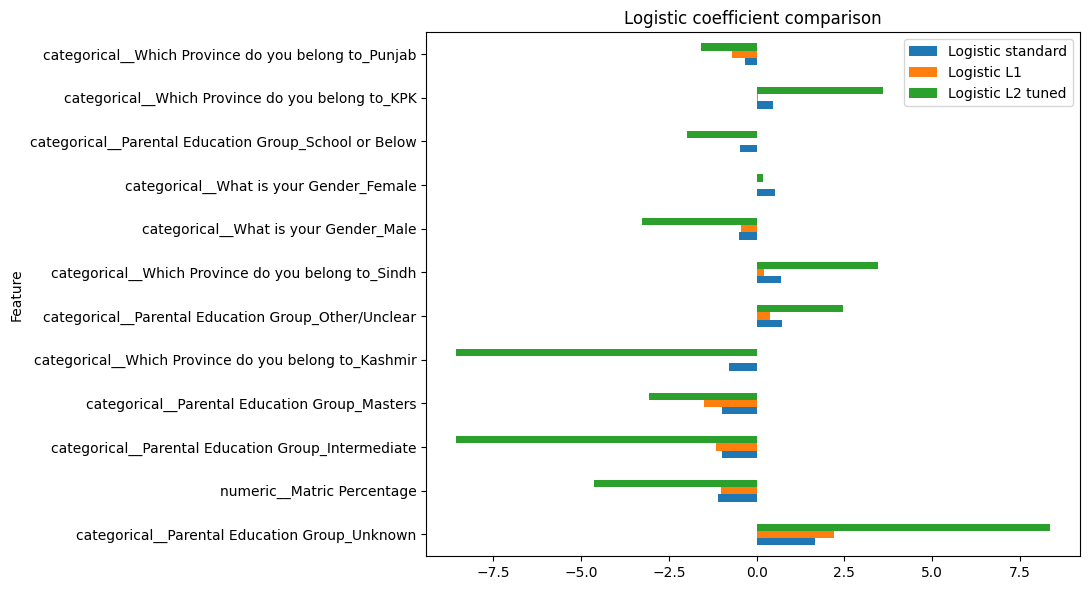

In [21]:
log_candidates={
    "Logistic standard":classification_models["Logistic Regression (Standard)"],
    "Logistic L1":classification_models["Logistic Regression (L1)"],
    "Logistic L2":classification_models["Logistic Regression (L2)"],
    "Logistic L1 tuned":classification_tuned["l1"],
    "Logistic L2 tuned":classification_tuned["l2"],
}
log_features=log_candidates["Logistic standard"].named_steps["preprocess"].get_feature_names_out()
logistic_coefficients=pd.DataFrame({"Feature":log_features})
for name,model in log_candidates.items():
    logistic_coefficients[name]=model.named_steps["model"].coef_[0]
print("Logistic coefficients:");display(logistic_coefficients.round(4))
print("Top positive risk associations:");display(logistic_coefficients.nlargest(5,"Logistic standard")[["Feature","Logistic standard"]].round(4))
print("Top negative risk associations:");display(logistic_coefficients.nsmallest(5,"Logistic standard")[["Feature","Logistic standard"]].round(4))
print("L1 near-zero coefficients:",int(np.isclose(logistic_coefficients["Logistic L1"],0,atol=1e-7).sum()))
plot_log=logistic_coefficients.assign(abs_coef=lambda d:d["Logistic standard"].abs()).nlargest(12,"abs_coef")
plot_log.set_index("Feature")[["Logistic standard","Logistic L1","Logistic L2 tuned"]].plot(kind="barh",figsize=(11,6))
plt.title("Logistic coefficient comparison");plt.tight_layout();plt.show()

## Step 19 — Actual vs Predicted: Diagnostics and Misclassified Cases
All predictions are from the unchanged held-out test set. No model or decision threshold is tuned on these test outcomes.

Full held-out actual vs predicted table:


,Test Student,Actual UG CGPA,Predicted UG CGPA,Actual Risk,Predicted Risk L1,Predicted Risk L2,Risk Probability L1,Risk Probability L2,CGPA Absolute Error,L1 Correct,L2 Correct
0,1,2.76,2.8338,0,0,0,0.0000,0.0216,0.0738,True,True
1,2,3.13,2.5368,0,1,1,1.0000,0.9997,0.5932,False,False
2,3,3.07,3.0015,0,0,0,0.0000,0.0002,0.0685,True,True
3,4,3.49,3.2770,0,0,0,0.0000,0.0000,0.2130,True,True
4,5,3.30,3.1593,0,0,0,0.0000,0.0007,0.1407,True,True
5,6,3.59,3.3465,0,0,0,0.0000,0.0000,0.2435,True,True
6,7,3.30,3.2212,0,0,0,0.0000,0.0003,0.0788,True,True
7,8,3.53,3.2247,0,0,0,0.0000,0.0000,0.3053,True,True
8,9,2.62,2.8193,0,0,0,0.0002,0.0068,0.1993,True,True
9,10,2.90,3.0785,0,0,0,0.0000,0.0112,0.1785,True,True


Two misclassified cases (if available):


,Test Student,Actual UG CGPA,Predicted UG CGPA,Actual Risk,Predicted Risk L1,Predicted Risk L2,Risk Probability L1,Risk Probability L2,CGPA Absolute Error,L1 Correct,L2 Correct
1,2,3.13,2.5368,0,1,1,1.0,0.9997,0.5932,False,False


Fewer than two L2 errors occurred; no additional cases invented.


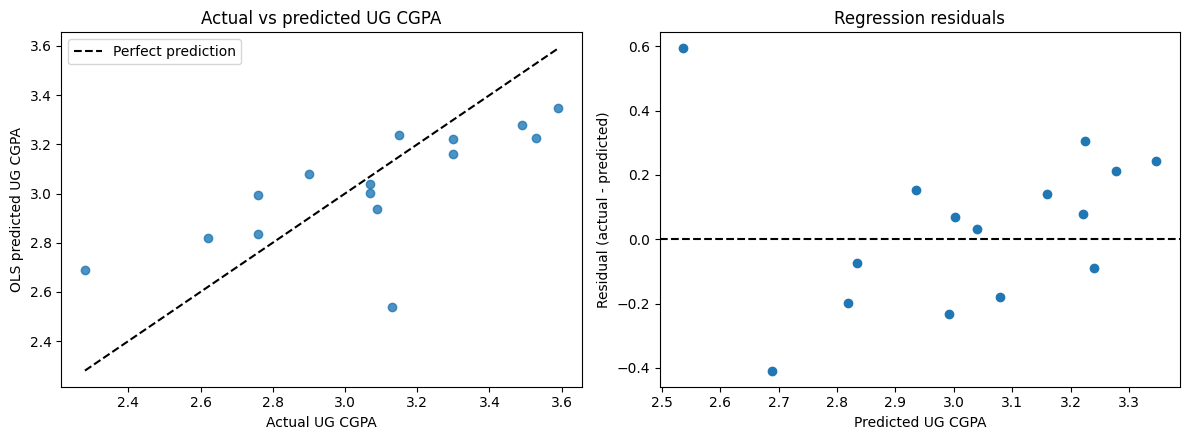

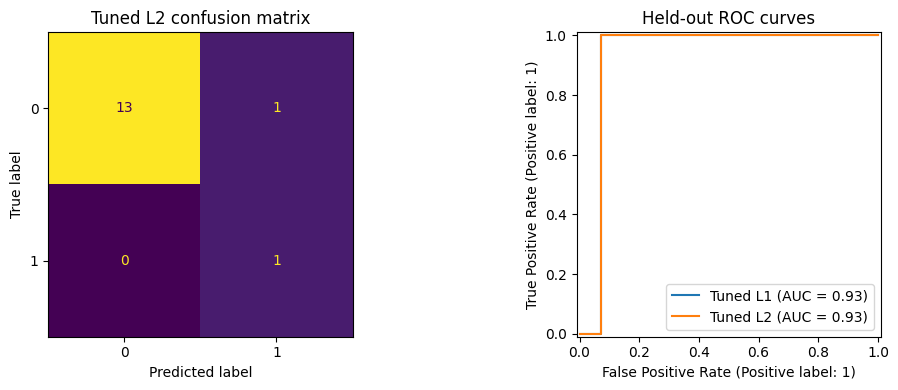

Test regression MAE: 0.2006


In [22]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, mean_absolute_error
# Student-level comparison from Step 16
print("Full held-out actual vs predicted table:")
display(test_evaluation.round(4))
print("Two misclassified cases (if available):")
errors=test_evaluation.loc[~test_evaluation["L2 Correct"]].head(2)
display(errors.round(4))
if len(errors)<2:
    print("Fewer than two L2 errors occurred; no additional cases invented.")
fig,axs=plt.subplots(1,2,figsize=(12,4.5))
axs[0].scatter(test_evaluation["Actual UG CGPA"],test_evaluation["Predicted UG CGPA"],alpha=.8)
lo=min(test_evaluation["Actual UG CGPA"].min(),test_evaluation["Predicted UG CGPA"].min())
hi=max(test_evaluation["Actual UG CGPA"].max(),test_evaluation["Predicted UG CGPA"].max())
axs[0].plot([lo,hi],[lo,hi],"k--",label="Perfect prediction")
axs[0].set(xlabel="Actual UG CGPA",ylabel="OLS predicted UG CGPA",title="Actual vs predicted UG CGPA")
axs[0].legend()
axs[1].scatter(test_evaluation["Predicted UG CGPA"],test_evaluation["Actual UG CGPA"]-test_evaluation["Predicted UG CGPA"])
axs[1].axhline(0,color="black",linestyle="--")
axs[1].set(xlabel="Predicted UG CGPA",ylabel="Residual (actual - predicted)",title="Regression residuals")
plt.tight_layout();plt.show()
fig,axs=plt.subplots(1,2,figsize=(11,4))
ConfusionMatrixDisplay.from_estimator(classification_tuned["l2"],X_test,y_test_cls,labels=[0,1],ax=axs[0],colorbar=False)
axs[0].set_title("Tuned L2 confusion matrix")
RocCurveDisplay.from_estimator(classification_tuned["l1"],X_test,y_test_cls,ax=axs[1],name="Tuned L1")
RocCurveDisplay.from_estimator(classification_tuned["l2"],X_test,y_test_cls,ax=axs[1],name="Tuned L2")
axs[1].set_title("Held-out ROC curves")
plt.tight_layout();plt.show()
print("Test regression MAE:",round(mean_absolute_error(y_test,reg_model.predict(X_test)),4))

## Step 20 — Educational Implications, Limitations, and Requirement Verification

**Interpretation and possible interventions:** Prior academic percentages and parental education are possible correlates of UG CGPA. Explore targeted voluntary tutoring, academic advising, and study-skills resources based on direct assessment of academic need. Evaluate any intervention prospectively before making causal claims. Do not use gender, province, or parental background to deny educational opportunities.

**Limitations:** This self-reported dataset is small; the positive risk class is especially rare. Risk is defined using a UG CGPA threshold, not observed dropout. A single 15-student test set and 1 positive test case make recall, ROC-AUC, and subgroup conclusions unstable. Outlier flags are descriptive. Full one-hot coefficients are parameterization-dependent; associations are not causal. Data truncation compares smaller subsets but cannot guarantee monotonic improvement.

**Verification:** Missingness, outlier review, encoding, correlations/distributions, targets, OLS, Logistic Regression, Ridge/Lasso, L1/L2, CV tuning, model comparisons, coefficient interpretation, actual-versus-predicted diagnostics, misclassified cases, and educational implications are all covered.

In [23]:
assert len(X_train)+len(X_test)==len(model_df)
assert len(test_evaluation)==len(X_test)
assert len(regression_coefficients)==len(reg_candidates["OLS"].named_steps["model"].coef_)
assert len(logistic_coefficients)==len(log_candidates["Logistic standard"].named_steps["model"].coef_[0])
assert (test_evaluation["Actual Risk"].to_numpy()==np.asarray(y_test_cls)).all()
assert np.allclose(test_evaluation["Predicted UG CGPA"],reg_model.predict(X_test))
print("PASS: split, coefficient dimensions, student row alignment and predictions verified")
print("Train/test:",len(X_train),len(X_test),"| Test positives:",int(y_test_cls.sum()))

PASS: split, coefficient dimensions, student row alignment and predictions verified
Train/test: 59 15 | Test positives: 1
